In [10]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

def set_seed(s):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

SEED = 0
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

DATA_DIR = "."   # change to the folder that contains train.npz

device: cpu


In [11]:
d = np.load(f"/Users/vedbhatt/Desktop/AML/learning-physical-dynamics-across-resolutions-main 6.08.58 PM/data/train.npz")
u_in    = d["field"]          # (240, 128)
u_out   = d["target"]         # (240, 128)
t_start = d["context"][:, 0]  # start time of each example
x_grid  = d["coordinates"]    # (128,)

# the file has no trajectory id: rows come in blocks of 5 start times
traj_id = np.arange(len(u_in)) // 5
assert np.allclose(t_start.reshape(48, 5), [0, 0.2, 0.4, 0.6, 0.8]), "row order assumption broken"

print("inputs :", u_in.shape, " targets:", u_out.shape)
print("trajectories:", len(np.unique(traj_id)), " examples per trajectory:", 5)

# reference error of "predict that nothing changes"
identity_err = (np.linalg.norm(u_out - u_in, axis=1) / np.linalg.norm(u_out, axis=1)).mean()
print(f"identity baseline relative L2: {identity_err:.4f}")

inputs : (240, 128)  targets: (240, 128)
trajectories: 48  examples per trajectory: 5
identity baseline relative L2: 0.0289


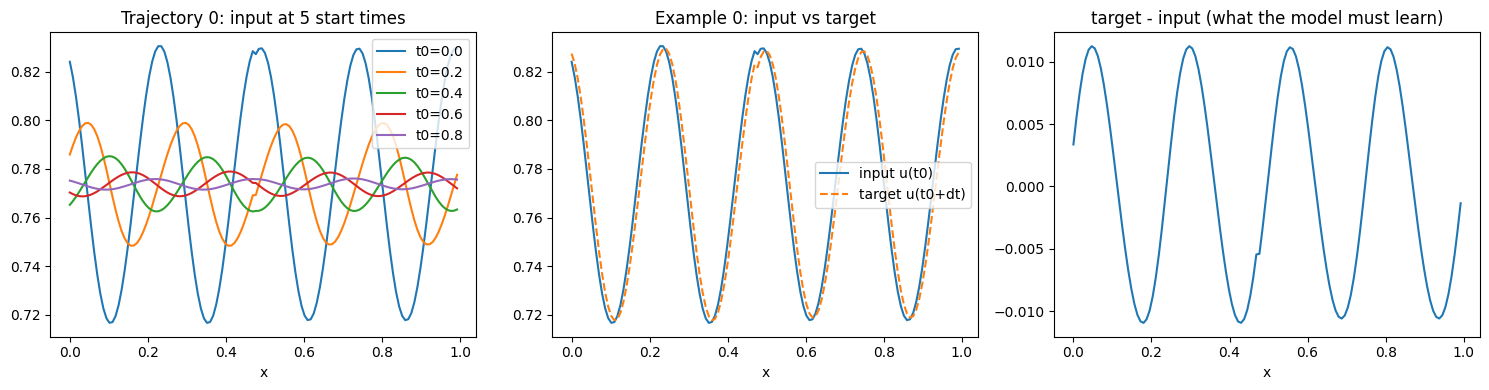

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# (a) one trajectory at its 5 start times
for j in range(5):
    ax[0].plot(x_grid, u_in[j], label=f"t0={t_start[j]:.1f}")
ax[0].set_title("Trajectory 0: input at 5 start times"); ax[0].set_xlabel("x"); ax[0].legend()

# (b) input vs target, example 0
ax[1].plot(x_grid, u_in[0], label="input u(t0)")
ax[1].plot(x_grid, u_out[0], "--", label="target u(t0+dt)")
ax[1].set_title("Example 0: input vs target"); ax[1].set_xlabel("x"); ax[1].legend()

# (c) the change the model has to learn, for the same example
ax[2].plot(x_grid, u_out[0] - u_in[0])
ax[2].set_title("target - input (what the model must learn)"); ax[2].set_xlabel("x")

plt.tight_layout(); plt.show()

In [13]:
def make_input(u):                          # u: (B, N) -> (B, N, 2)
    B, N = u.shape
    x = torch.linspace(0, 1, N + 1, device=u.device)[:-1]   # periodic: no endpoint
    x = x.expand(B, N)
    return torch.stack([u, x], dim=-1)

# quick check: our x channel must equal the file's coordinates
chk = make_input(torch.zeros(1, 128))
print("x channel matches file:", np.allclose(chk[0, :, 1].numpy(), x_grid))
print("input shape:", chk.shape)

x channel matches file: True
input shape: torch.Size([1, 128, 2])


In [14]:
rng = np.random.default_rng(0)                  # fixed: same split for every model seed
val_trajs = rng.choice(np.arange(48), size=8, replace=False)
val_mask = np.isin(traj_id, val_trajs)

def to_t(a): return torch.tensor(a, dtype=torch.float32, device=device)

Xtr, Ytr = to_t(u_in[~val_mask]), to_t(u_out[~val_mask])
Xva, Yva = to_t(u_in[val_mask]),  to_t(u_out[val_mask])

print("train:", Xtr.shape, " val:", Xva.shape)
print("val trajectories:", sorted(val_trajs))

train: torch.Size([200, 128])  val: torch.Size([40, 128])
val trajectories: [np.int64(0), np.int64(1), np.int64(3), np.int64(11), np.int64(13), np.int64(21), np.int64(26), np.int64(34)]


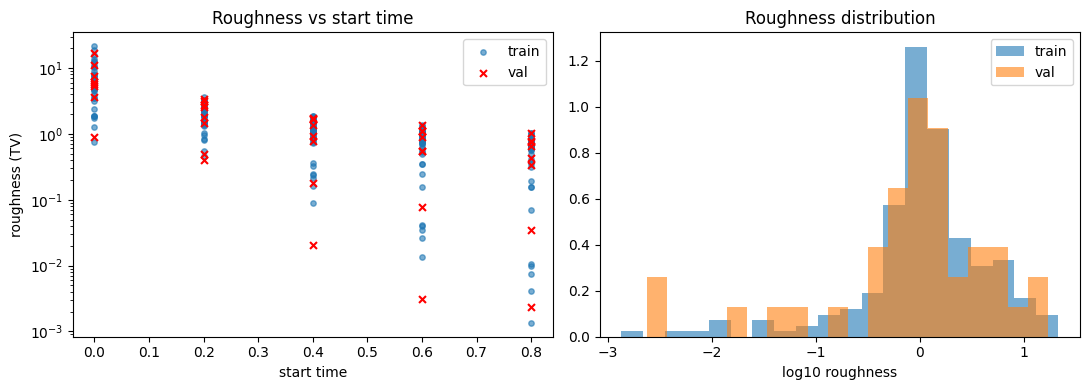

In [15]:
def roughness(u):                               # total variation, periodic
    return np.abs(np.roll(u, -1, axis=1) - u).sum(axis=1)

R = roughness(u_in)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(t_start[~val_mask], R[~val_mask], s=15, label="train", alpha=0.6)
ax[0].scatter(t_start[val_mask],  R[val_mask],  s=25, label="val", marker="x", color="red")
ax[0].set_yscale("log"); ax[0].set_xlabel("start time"); ax[0].set_ylabel("roughness (TV)")
ax[0].set_title("Roughness vs start time"); ax[0].legend()

ax[1].hist(np.log10(R[~val_mask]), bins=20, alpha=0.6, density=True, label="train")
ax[1].hist(np.log10(R[val_mask]),  bins=20, alpha=0.6, density=True, label="val")
ax[1].set_xlabel("log10 roughness"); ax[1].set_title("Roughness distribution"); ax[1].legend()

plt.tight_layout(); plt.show()

In [16]:
class SpectralConv1d(nn.Module):
    def __init__(self, in_c, out_c, modes):
        super().__init__()
        self.modes = modes
        scale = 1 / (in_c * out_c)
        self.weights = nn.Parameter(
            scale * torch.randn(in_c, out_c, modes, dtype=torch.cfloat))

    def forward(self, x):                        # x: (B, C, N)
        B, _, N = x.shape
        x_ft = torch.fft.rfft(x)                 # (B, C, N//2+1)
        out_ft = torch.zeros(B, self.weights.shape[1], N // 2 + 1,
                             dtype=torch.cfloat, device=x.device)
        k = min(self.modes, N // 2 + 1)
        out_ft[:, :, :k] = torch.einsum("bix,iox->box",
                                        x_ft[:, :, :k], self.weights[:, :, :k])
        return torch.fft.irfft(out_ft, n=N)      # (B, out_c, N)

In [17]:
class FNO1d(nn.Module):
    def __init__(self, modes=16, width=64, n_layers=4):
        super().__init__()
        self.lift = nn.Linear(2, width)
        self.spec = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(n_layers)])
        self.w    = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(n_layers)])
        self.proj = nn.Sequential(nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1))

    def forward(self, x):                        # x: (B, N, 2)
        x = self.lift(x).permute(0, 2, 1)        # (B, width, N)
        for s, w in zip(self.spec, self.w):
            x = nn.functional.gelu(s(x) + w(x))
        x = x.permute(0, 2, 1)                   # (B, N, width)
        return self.proj(x).squeeze(-1)          # (B, N)

model = FNO1d(modes=16, width=64, n_layers=4).to(device)
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 287425


output shapes: torch.Size([4, 128]) torch.Size([4, 256])
relative difference between grids: [5.7598032e-07 5.8574676e-07 5.8952719e-07 5.7077125e-07]


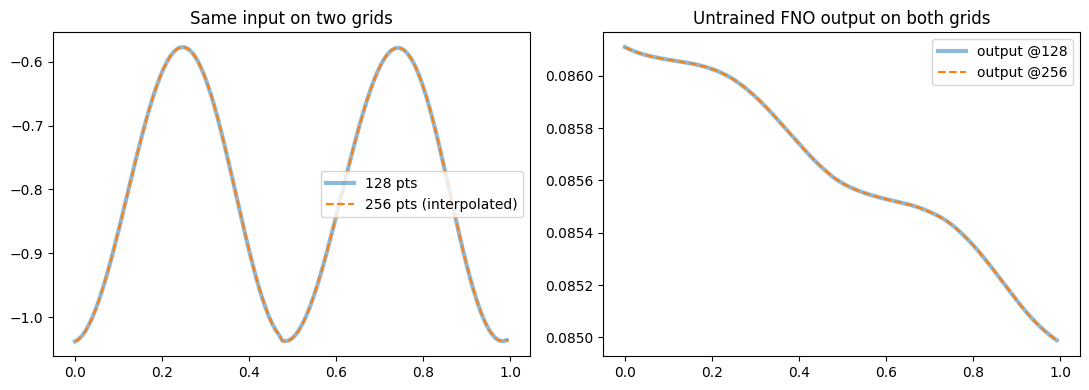

In [18]:
def upsample(u, factor):                         # exact Fourier interpolation, u: (B, N)
    N = u.shape[-1]
    U = torch.fft.rfft(u)
    Up = torch.zeros(u.shape[0], N * factor // 2 + 1, dtype=torch.cfloat, device=u.device)
    Up[:, :U.shape[-1]] = U
    return torch.fft.irfft(Up, n=N * factor) * factor

u128 = Xtr[:4]                                   # 4 training inputs
u256 = upsample(u128, 2)

model.eval()
with torch.no_grad():
    y128 = model(make_input(u128))               # (4, 128)
    y256 = model(make_input(u256))               # (4, 256)

print("output shapes:", y128.shape, y256.shape)
diff = (y256[:, ::2] - y128).norm(dim=-1) / y128.norm(dim=-1)
print("relative difference between grids:", diff.cpu().numpy())

x128 = np.linspace(0, 1, 128, endpoint=False)
x256 = np.linspace(0, 1, 256, endpoint=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(x128, u128[0].cpu(), label="128 pts", lw=3, alpha=0.5)
ax[0].plot(x256, u256[0].cpu(), "--", label="256 pts (interpolated)")
ax[0].set_title("Same input on two grids"); ax[0].legend()
ax[1].plot(x128, y128[0].cpu(), label="output @128", lw=3, alpha=0.5)
ax[1].plot(x256, y256[0].cpu(), "--", label="output @256")
ax[1].set_title("Untrained FNO output on both grids"); ax[1].legend()
plt.tight_layout(); plt.show()

In [19]:
def rel_l2(pred, target):                        # per-sample relative L2, then mean
    num = torch.linalg.vector_norm(pred - target, dim=-1)
    den = torch.linalg.vector_norm(target, dim=-1)
    return (num / den).mean()

# reference points
with torch.no_grad():
    print("untrained model, val loss:", rel_l2(model(make_input(Xva)), Yva).item())
    print("identity baseline, val loss:", rel_l2(Xva, Yva).item())

untrained model, val loss: 1.0767161846160889
identity baseline, val loss: 0.02850143052637577


In [20]:
set_seed(0)
m = FNO1d(modes=16, width=64, n_layers=4).to(device)    # fresh copy, `model` stays untouched
opt_s = torch.optim.Adam(m.parameters(), lr=1e-3)

xb, yb = Xtr[:16], Ytr[:16]
inp = make_input(xb)
hist = []
for step in range(1000):
    loss = rel_l2(m(inp), yb)
    opt_s.zero_grad(); loss.backward(); opt_s.step()
    hist.append(loss.item())
    if step % 100 == 0:
        print(step, f"{hist[-1]:.5f}")
print("final:", hist[-1])

0 1.07641
100 0.03306
200 0.01362
300 0.03799
400 0.02003
500 0.01615
600 0.01706
700 0.01608
800 0.01903
900 0.01635
final: 0.00955289788544178


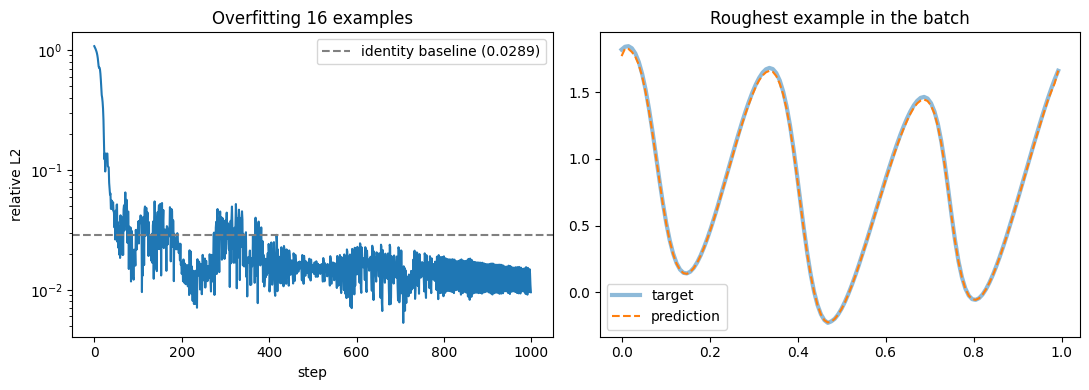

In [21]:
m.eval()
with torch.no_grad():
    pred = m(inp)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(hist)
ax[0].axhline(0.0289, color="gray", ls="--", label="identity baseline (0.0289)")
ax[0].set_xlabel("step"); ax[0].set_ylabel("relative L2"); ax[0].set_title("Overfitting 16 examples"); ax[0].legend()

i = int(np.argmax(roughness(xb.cpu().numpy())))          # roughest example in the batch
ax[1].plot(x_grid, yb[i].cpu(), label="target", lw=3, alpha=0.5)
ax[1].plot(x_grid, pred[i].cpu(), "--", label="prediction")
ax[1].set_title("Roughest example in the batch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [22]:
set_seed(SEED)
model = FNO1d(modes=16, width=64, n_layers=4).to(device)   # fresh model
epochs, bs = 500, 16
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

tr_hist, va_hist = [], []
best_va, best_ep, best_state = float("inf"), -1, None

for ep in range(epochs):
    model.train()
    perm = torch.randperm(len(Xtr), device=device)
    for i in range(0, len(Xtr), bs):
        idx = perm[i:i + bs]
        loss = rel_l2(model(make_input(Xtr[idx])), Ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    sched.step()

    model.eval()
    with torch.no_grad():
        tr = rel_l2(model(make_input(Xtr)), Ytr).item()
        va = rel_l2(model(make_input(Xva)), Yva).item()
    tr_hist.append(tr); va_hist.append(va)
    if va < best_va:
        best_va, best_ep = va, ep
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    if ep % 25 == 0 or ep == epochs - 1:
        print(f"epoch {ep:3d}  train {tr:.5f}  val {va:.5f}")

print(f"\nbest val {best_va:.5f} at epoch {best_ep}   |   final val {va_hist[-1]:.5f}")

epoch   0  train 0.85013  val 0.84251
epoch  25  train 0.04043  val 0.04380
epoch  50  train 0.03443  val 0.02874
epoch  75  train 0.02657  val 0.02935
epoch 100  train 0.03699  val 0.03555
epoch 125  train 0.04369  val 0.04070
epoch 150  train 0.01662  val 0.01621
epoch 175  train 0.01998  val 0.02015
epoch 200  train 0.01336  val 0.01561
epoch 225  train 0.02011  val 0.02074
epoch 250  train 0.00784  val 0.00917
epoch 275  train 0.00865  val 0.01152
epoch 300  train 0.01151  val 0.01264
epoch 325  train 0.00591  val 0.00741
epoch 350  train 0.01056  val 0.01500
epoch 375  train 0.00877  val 0.01011
epoch 400  train 0.00660  val 0.00856
epoch 425  train 0.00377  val 0.00614
epoch 450  train 0.00354  val 0.00574
epoch 475  train 0.00305  val 0.00524
epoch 499  train 0.00304  val 0.00521

best val 0.00521 at epoch 480   |   final val 0.00521


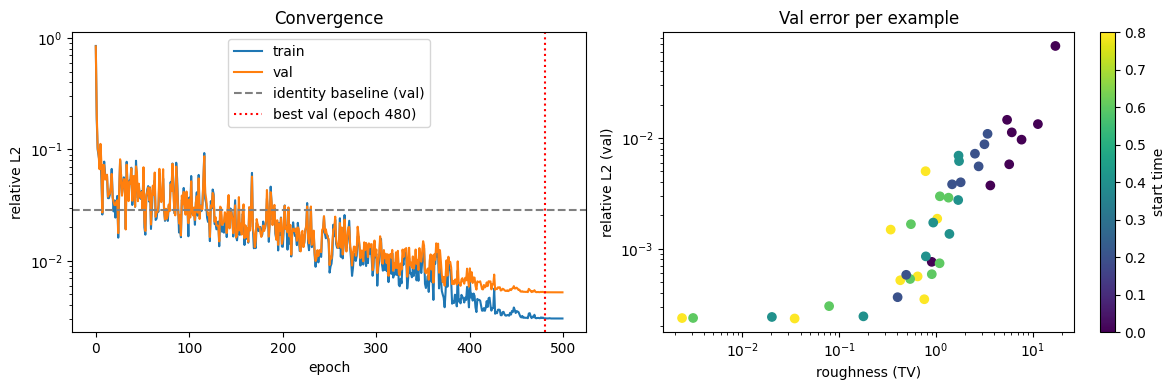

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(tr_hist, label="train"); ax[0].semilogy(va_hist, label="val")
ax[0].axhline(0.0285, color="gray", ls="--", label="identity baseline (val)")
ax[0].axvline(best_ep, color="red", ls=":", label=f"best val (epoch {best_ep})")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("relative L2"); ax[0].set_title("Convergence"); ax[0].legend()

# per-example validation error, coloured by start time
model.eval()
with torch.no_grad():
    pv = model(make_input(Xva))
    per_ex = (torch.linalg.vector_norm(pv - Yva, dim=-1) / torch.linalg.vector_norm(Yva, dim=-1)).cpu().numpy()
sc = ax[1].scatter(roughness(Xva.cpu().numpy()), per_ex, c=t_start[val_mask], cmap="viridis")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("roughness (TV)"); ax[1].set_ylabel("relative L2 (val)")
ax[1].set_title("Val error per example"); plt.colorbar(sc, label="start time")
plt.tight_layout(); plt.show()

In [24]:
torch.save({"state": model.state_dict(),
            "config": dict(modes=16, width=64, n_layers=4),
            "seed": SEED, "epochs": epochs,
            "val_trajs": val_trajs.tolist(),
            "train_hist": tr_hist, "val_hist": va_hist},
           "fno_seed0.pt")
print("saved fno_seed0.pt, final val:", va_hist[-1])

saved fno_seed0.pt, final val: 0.005213484168052673


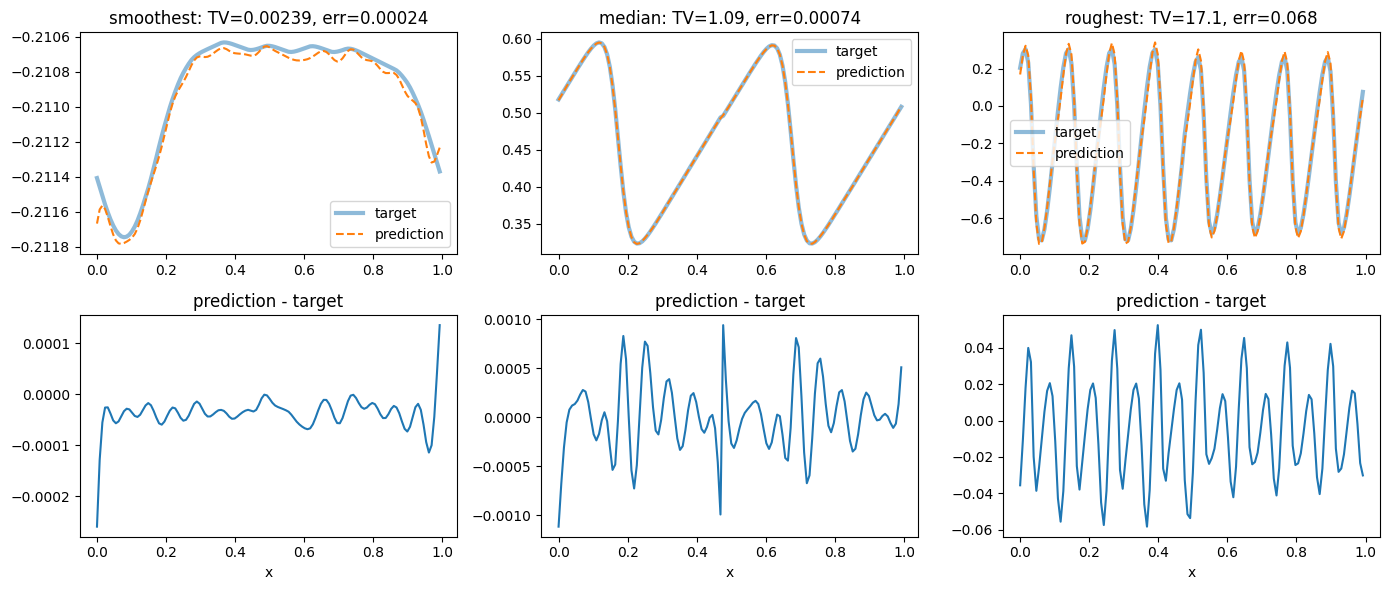

In [25]:
R_va = roughness(Xva.cpu().numpy())
order = np.argsort(R_va)
picks = [order[0], order[len(order)//2], order[-1]]
names = ["smoothest", "median", "roughest"]

model.eval()
with torch.no_grad():
    pv = model(make_input(Xva))

fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for j, (i, nm) in enumerate(zip(picks, names)):
    y, p = Yva[i].cpu().numpy(), pv[i].cpu().numpy()
    ax[0, j].plot(x_grid, y, lw=3, alpha=0.5, label="target")
    ax[0, j].plot(x_grid, p, "--", label="prediction")
    ax[0, j].set_title(f"{nm}: TV={R_va[i]:.3g}, err={per_ex[i]:.2g}"); ax[0, j].legend()
    ax[1, j].plot(x_grid, p - y); ax[1, j].set_title("prediction - target"); ax[1, j].set_xlabel("x")
plt.tight_layout(); plt.show()

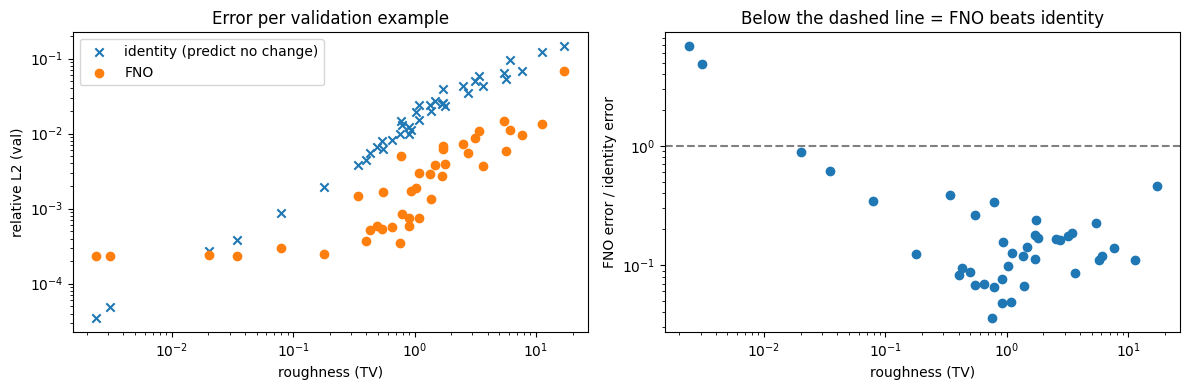

examples where FNO is worse than identity: 2 of 40


In [26]:
def per_sample(p, y):
    return (torch.linalg.vector_norm(p - y, dim=-1) / torch.linalg.vector_norm(y, dim=-1)).cpu().numpy()

model.eval()
with torch.no_grad():
    err_model = per_sample(model(make_input(Xva)), Yva)
err_ident = per_sample(Xva, Yva)
R_va = roughness(Xva.cpu().numpy())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(R_va, err_ident, marker="x", label="identity (predict no change)")
ax[0].scatter(R_va, err_model, label="FNO")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("roughness (TV)"); ax[0].set_ylabel("relative L2 (val)"); ax[0].legend()
ax[0].set_title("Error per validation example")

ax[1].scatter(R_va, err_model / err_ident)
ax[1].axhline(1, color="gray", ls="--")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("roughness (TV)"); ax[1].set_ylabel("FNO error / identity error")
ax[1].set_title("Below the dashed line = FNO beats identity")
plt.tight_layout(); plt.show()

print("examples where FNO is worse than identity:", int((err_model > err_ident).sum()), "of", len(err_model))

In [27]:
import time, os

Xall, Yall = to_t(u_in), to_t(u_out)             # all 240 examples (48 trajectories)

def train_fno(seed, X, Y, epochs=500, bs=16, lr=1e-3, wd=1e-4,
              modes=16, width=64, n_layers=4, verbose=True):
    set_seed(seed)
    net = FNO1d(modes=modes, width=width, n_layers=n_layers).to(device)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = []
    t0 = time.time()
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(len(X), device=device)
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]
            loss = rel_l2(net(make_input(X[idx])), Y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        net.eval()
        with torch.no_grad():
            hist.append(rel_l2(net(make_input(X)), Y).item())
        if verbose and (ep % 50 == 0 or ep == epochs - 1):
            print(f"seed {seed}  epoch {ep:3d}  train {hist[-1]:.5f}  ({time.time()-t0:.0f}s)")
    cfg = dict(modes=modes, width=width, n_layers=n_layers)
    return net, hist, cfg

def save_ckpt(net, hist, cfg, seed, path):
    torch.save({"state": net.state_dict(), "config": cfg, "seed": seed,
                "epochs": len(hist), "train_hist": hist,
                "data": "all 48 train trajectories"}, path)

In [28]:
print("device:", device)
t0 = time.time()
_ = train_fno(seed=123, X=Xall, Y=Yall, epochs=5, verbose=False)
per_epoch = (time.time() - t0) / 5
print(f"{per_epoch:.2f} s/epoch  ->  ~{per_epoch*500/60:.1f} min per seed,  ~{per_epoch*500*5/60:.0f} min for 5 seeds")

device: cpu
0.39 s/epoch  ->  ~3.3 min per seed,  ~16 min for 5 seeds


seed 0  epoch   0  train 0.74961  (0s)
seed 0  epoch  50  train 0.03647  (20s)
seed 0  epoch 100  train 0.04062  (40s)
seed 0  epoch 150  train 0.01690  (60s)
seed 0  epoch 200  train 0.01692  (80s)
seed 0  epoch 250  train 0.01083  (100s)
seed 0  epoch 300  train 0.01355  (121s)
seed 0  epoch 350  train 0.00466  (141s)
seed 0  epoch 400  train 0.00444  (161s)
seed 0  epoch 450  train 0.00322  (182s)
seed 0  epoch 499  train 0.00304  (202s)


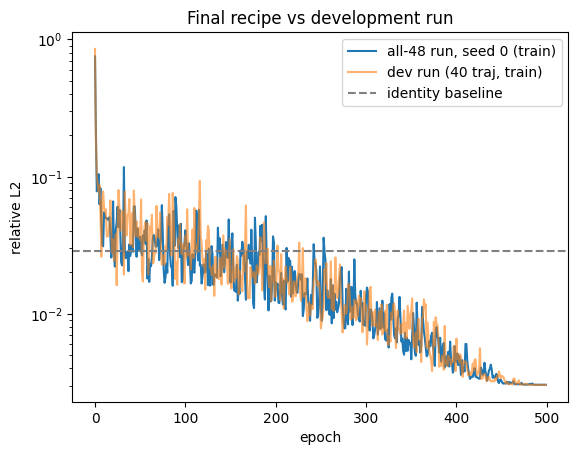

final train loss: 0.003042598720639944


In [29]:
net0, hist0, cfg = train_fno(seed=0, X=Xall, Y=Yall)
save_ckpt(net0, hist0, cfg, 0, "fno_all48_seed0.pt")

plt.semilogy(hist0, label="all-48 run, seed 0 (train)")
plt.semilogy(tr_hist, alpha=0.6, label="dev run (40 traj, train)")
plt.axhline(0.0289, color="gray", ls="--", label="identity baseline")
plt.xlabel("epoch"); plt.ylabel("relative L2"); plt.title("Final recipe vs development run")
plt.legend(); plt.show()
print("final train loss:", hist0[-1])

Below 2 cells are yet to run it is suggesion from Clude, to use more than one model to optimize comparision 


In [ ]:
all_hist = {0: hist0}
for s in [1, 2, 3, 4]:
    net, h, cfg = train_fno(seed=s, X=Xall, Y=Yall, verbose=False)
    save_ckpt(net, h, cfg, s, f"fno_all48_seed{s}.pt")
    all_hist[s] = h
    print(f"seed {s} done, final train loss {h[-1]:.5f}")

seed 1 done, final train loss 0.00301


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s, h in all_hist.items():
    ax[0].semilogy(h, alpha=0.7, label=f"seed {s}")
ax[0].axhline(0.0289, color="gray", ls="--", label="identity baseline")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("train relative L2"); ax[0].set_title("All seeds"); ax[0].legend()

finals = [all_hist[s][-1] for s in sorted(all_hist)]
ax[1].bar(sorted(all_hist), finals)
ax[1].set_xlabel("seed"); ax[1].set_ylabel("final train relative L2"); ax[1].set_title("Final loss per seed")
plt.tight_layout(); plt.show()
print("final losses:", [f"{f:.5f}" for f in finals])
print(f"mean {np.mean(finals):.5f}   std {np.std(finals):.5f}")